# Court Outcomes Research: Full Visualizations
This notebook contains the complete Python code to generate every single diagram from the analysis.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, auc
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('notebook', font_scale=1.1)
COLOR_PALETTE = 'viridis'

BASE_DIR = '/Users/purevjavgerel/Desktop/analysis/research/analysis'
DATA_FILE = os.path.join(BASE_DIR, 'cases/output.csv')
TABLES_DIR = os.path.join(BASE_DIR, 'output/tables')

# Load First-Instance Data
df = pd.read_csv(DATA_FILE, encoding='utf-8-sig')
fi = df[(df.case_level == 'first_instance') & (df.civil_outcome.notna())].copy()
if 'decision_date' in fi.columns:
    fi['decision_date'] = pd.to_datetime(fi['decision_date'], errors='coerce')
    fi['year'] = fi['decision_date'].dt.year

## 1. Cases by Year

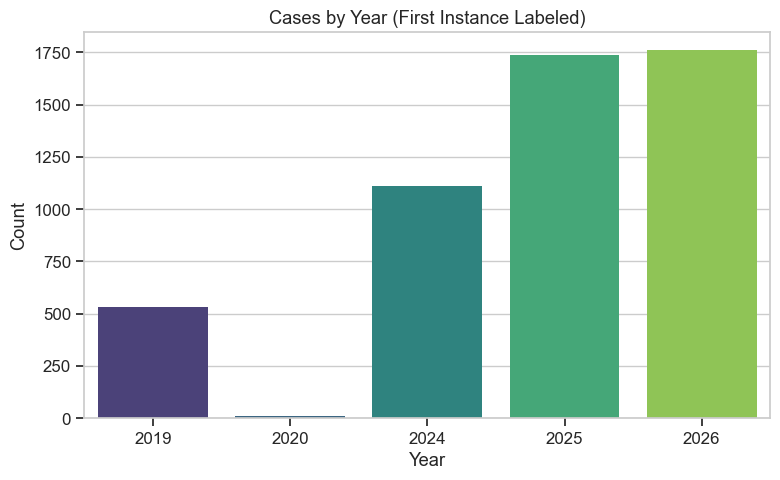

In [2]:
plt.figure(figsize=(8, 5))
if 'year' in fi.columns:
    year_counts = fi['year'].value_counts().sort_index()
    sns.barplot(x=year_counts.index.astype(int), y=year_counts.values, palette=COLOR_PALETTE)
    plt.title('Cases by Year (First Instance Labeled)')
    plt.ylabel('Count')
    plt.xlabel('Year')
    plt.tight_layout()
    plt.show()

## 2. Target Class Distribution

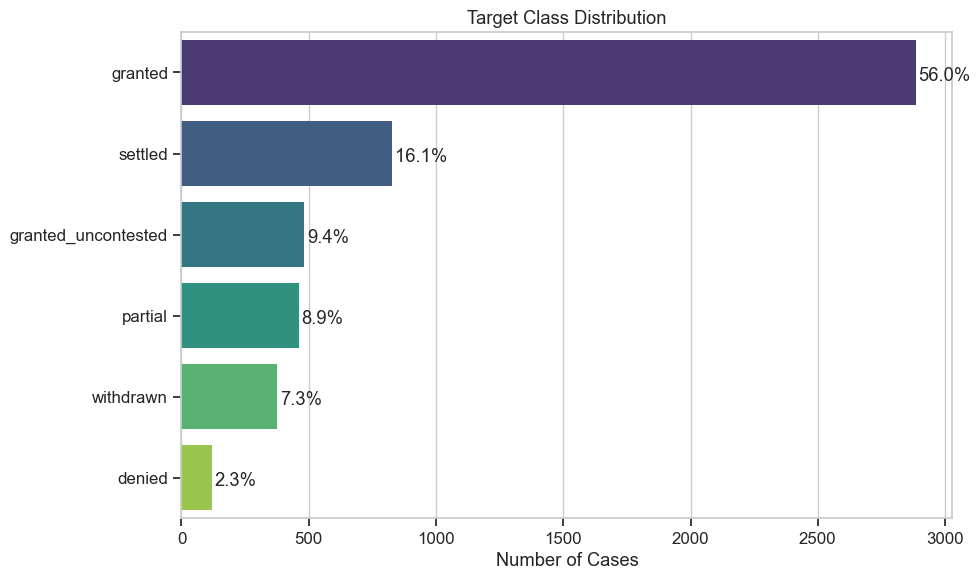

In [3]:
target_dist = pd.read_csv(f"{TABLES_DIR}/02_target_distribution.csv")
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='count', y='target_class', data=target_dist, palette=COLOR_PALETTE)
plt.title('Target Class Distribution')
plt.xlabel('Number of Cases')
plt.ylabel('')
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 10, p.get_y() + p.get_height()/2. + 0.1, '{:1.1f}%'.format((width/len(fi))*100), ha='left')
plt.tight_layout()
plt.show()

## 3. Missing Values Percentage by Feature

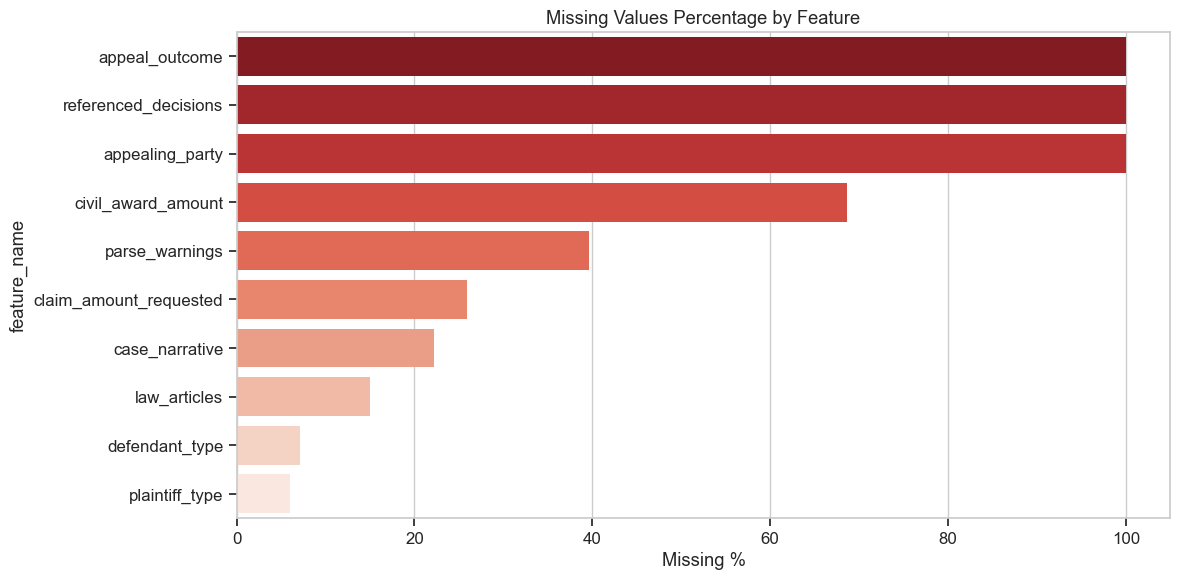

In [4]:
quality_df = pd.read_csv(f"{TABLES_DIR}/04_data_quality.csv")
plt.figure(figsize=(12, 6))
missing_plot = quality_df[quality_df.missing_count > 0].sort_values('missing_percentage', ascending=False)
if not missing_plot.empty:
    sns.barplot(x='missing_percentage', y='feature_name', data=missing_plot, palette='Reds_r')
    plt.title('Missing Values Percentage by Feature')
    plt.xlabel('Missing %')
    plt.tight_layout()
    plt.show()

## 4. Top 15 Feature Associations with Outcome

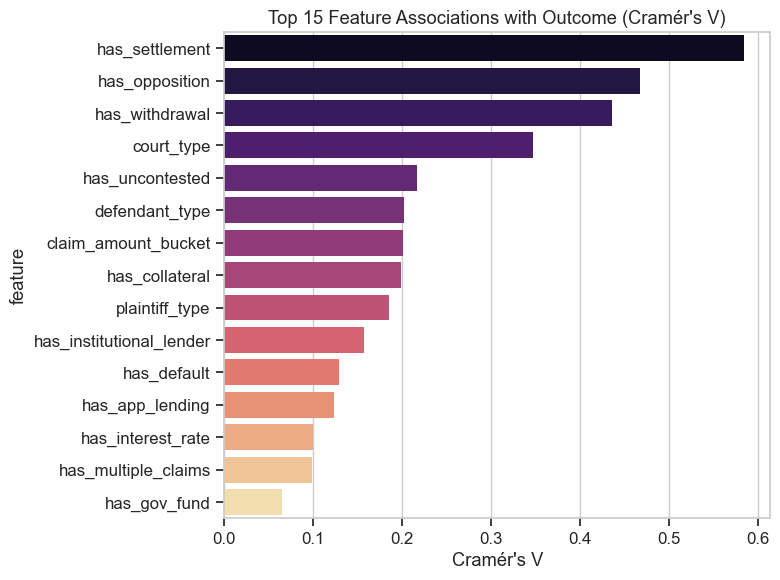

In [5]:
assoc_matrix = pd.read_csv(f"{TABLES_DIR}/06_feature_association_matrix.csv")
plt.figure(figsize=(8, 6))
sns.barplot(x='cramers_v_vs_outcome', y='feature', data=assoc_matrix.head(15), palette='magma')
plt.title("Top 15 Feature Associations with Outcome (Cramér's V)")
plt.xlabel("Cramér's V")
plt.tight_layout()
plt.show()

## 5. Feature Distributions by Outcome (Boxplots)

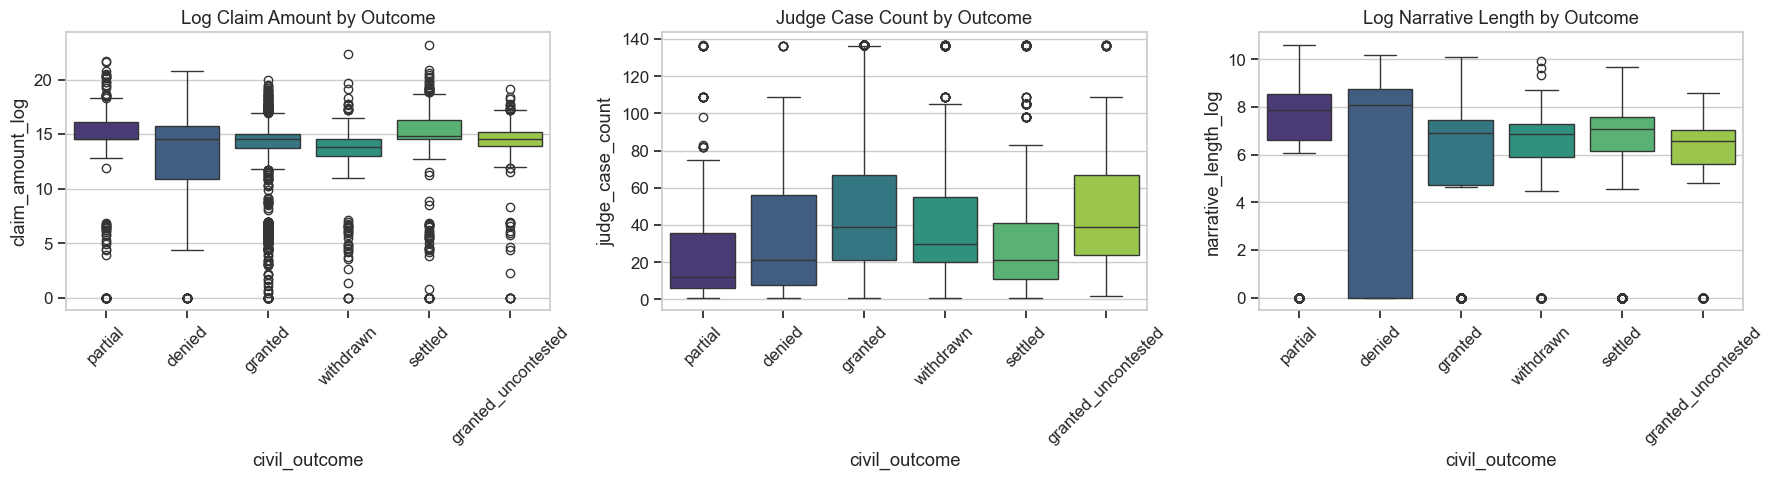

In [6]:
fi['claim_amount_log'] = np.log1p(fi['claim_amount_requested'].fillna(fi['claim_amount_requested'].median()))
fi['judge_case_count'] = fi.groupby('judge')['case_id'].transform('count')
fi['narrative_length_log'] = np.log1p(fi['case_narrative'].str.len().fillna(0))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x='civil_outcome', y='claim_amount_log', data=fi, ax=axes[0], palette=COLOR_PALETTE)
axes[0].set_title('Log Claim Amount by Outcome')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(x='civil_outcome', y='judge_case_count', data=fi, ax=axes[1], palette=COLOR_PALETTE)
axes[1].set_title('Judge Case Count by Outcome')
axes[1].tick_params(axis='x', rotation=45)

sns.boxplot(x='civil_outcome', y='narrative_length_log', data=fi, ax=axes[2], palette=COLOR_PALETTE)
axes[2].set_title('Log Narrative Length by Outcome')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 6. Model Version vs Macro-F1

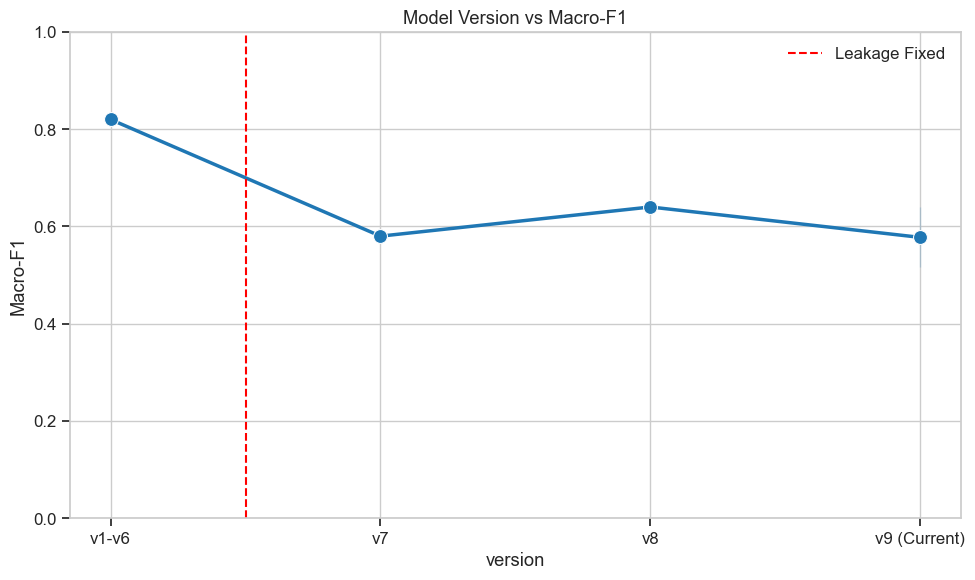

In [7]:
versions = pd.read_csv(f"{TABLES_DIR}/09_model_version_comparison.csv")
plt.figure(figsize=(10, 6))
plot_vers = versions[~versions.version.str.contains('Calibrated')].copy()
sns.lineplot(x='version', y='macro_f1', data=plot_vers, marker='o', linewidth=2.5, markersize=10)
plt.axvline(x=0.5, color='red', linestyle='--', label='Leakage Fixed')
plt.title('Model Version vs Macro-F1')
plt.ylabel('Macro-F1')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Cross-Validation Macro-F1 by Model

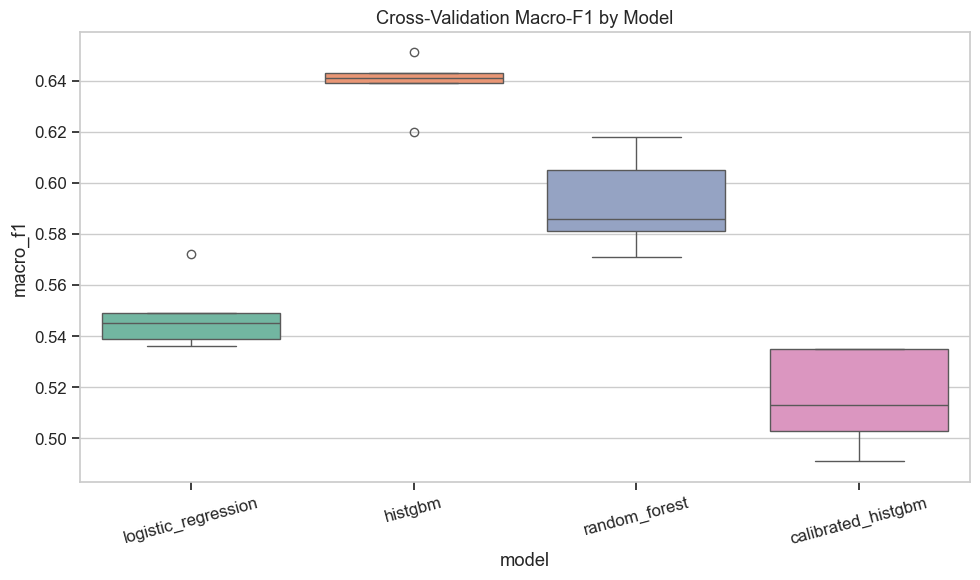

In [8]:
cv_df = pd.read_csv(f"{TABLES_DIR}/10_cv_results.csv")
melted = cv_df.melt(id_vars=['fold'], var_name='model', value_name='macro_f1')
plt.figure(figsize=(10, 6))
sns.boxplot(x='model', y='macro_f1', data=melted, palette='Set2')
plt.title('Cross-Validation Macro-F1 by Model')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 7.1. Cross-Validation Accuracy by Model

In [9]:
import os
acc_file = f"{TABLES_DIR}/10_cv_accuracy.csv"
if os.path.exists(acc_file):
    cv_acc_df = pd.read_csv(acc_file)
    melted_acc = cv_acc_df.melt(id_vars=['fold'], var_name='model', value_name='accuracy')
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='model', y='accuracy', data=melted_acc, palette='Set3')
    plt.title('Cross-Validation Accuracy by Model')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
else:
    print('Per-fold accuracy file not yet generated. Awaiting background analysis_phase2.py to finish.')

Per-fold accuracy file not yet generated. Awaiting background analysis_phase2.py to finish.


## 7.5 Overall Model Comparison (Macro-F1 & Accuracy)

Model,Macro-F1,Accuracy
naive_baseline,0.120,0.560
logistic_regression,0.548,0.658
random_forest,0.592,0.751
histgbm,0.639,0.768
calibrated_histgbm,0.516,0.738


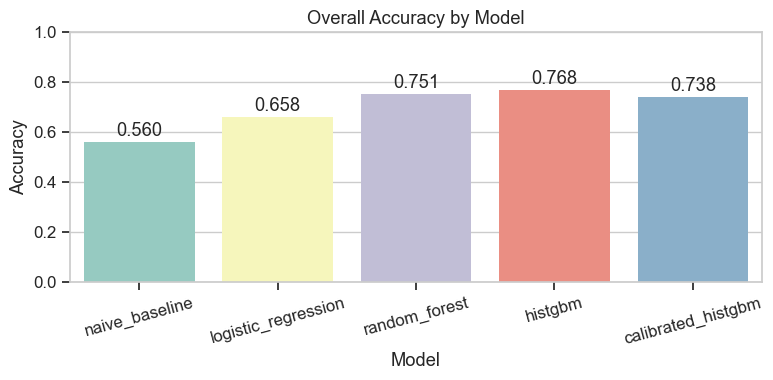


Overall HistGradientBoosting Accuracy: 0.768 (Matches ~76.8% used in the paper)


In [10]:
comp_df = pd.read_csv(f"{TABLES_DIR}/10_model_comparison.csv")
display_df = comp_df[['model', 'macro_f1', 'accuracy']].copy()
display_df.columns = ['Model', 'Macro-F1', 'Accuracy']

from IPython.display import display
display(display_df.style.format({'Macro-F1': '{:.3f}', 'Accuracy': '{:.3f}'}).hide(axis='index'))

# Separate compact Accuracy comparison figure
plt.figure(figsize=(8, 4))
sns.barplot(x='Model', y='Accuracy', data=display_df, palette='Set3')
plt.title('Overall Accuracy by Model')
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
for p in plt.gca().patches:
    plt.gca().text(p.get_x() + p.get_width()/2., p.get_height() + 0.01, f'{p.get_height():.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

# Verify HistGradientBoosting accuracy
hgb_acc = display_df.loc[display_df['Model'] == 'histgbm', 'Accuracy'].values[0]
print(f'\nOverall HistGradientBoosting Accuracy: {hgb_acc:.3f} (Matches ~76.8% used in the paper)')

## 8. Top 25 Feature Importances

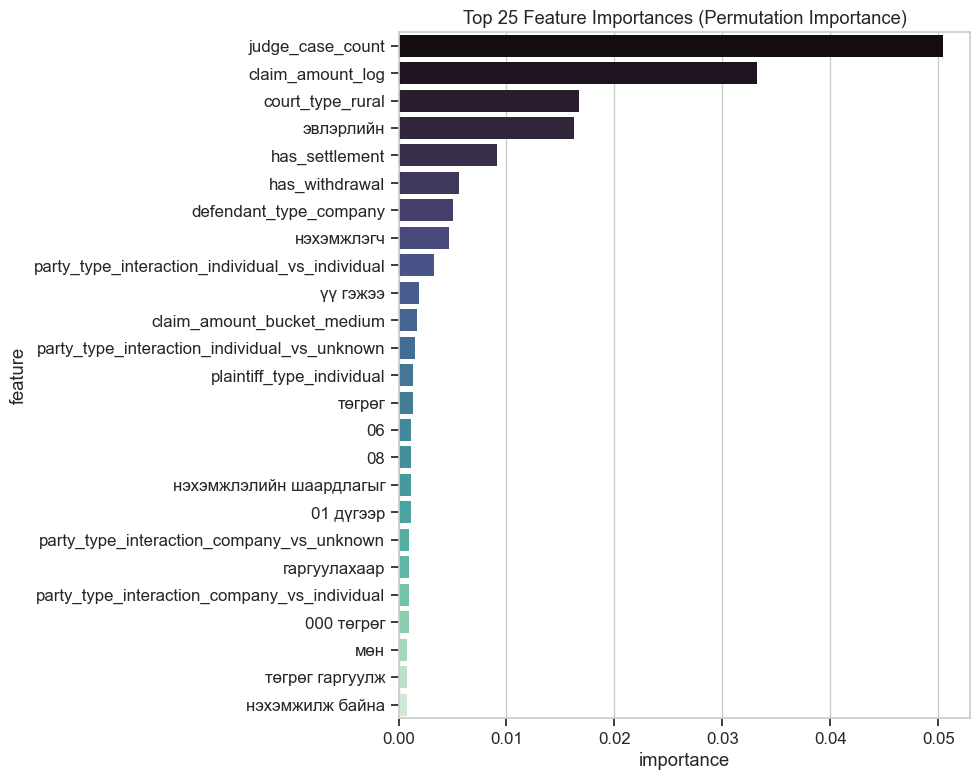

In [11]:
fi_df = pd.read_csv(f"{TABLES_DIR}/11_feature_importance.csv")
plt.figure(figsize=(10, 8))
sns.barplot(x='importance', y='feature', data=fi_df.head(25), palette='mako')
plt.title('Top 25 Feature Importances (Permutation Importance)')
plt.tight_layout()
plt.show()

## 9. Top 25 TF-IDF Terms by Importance

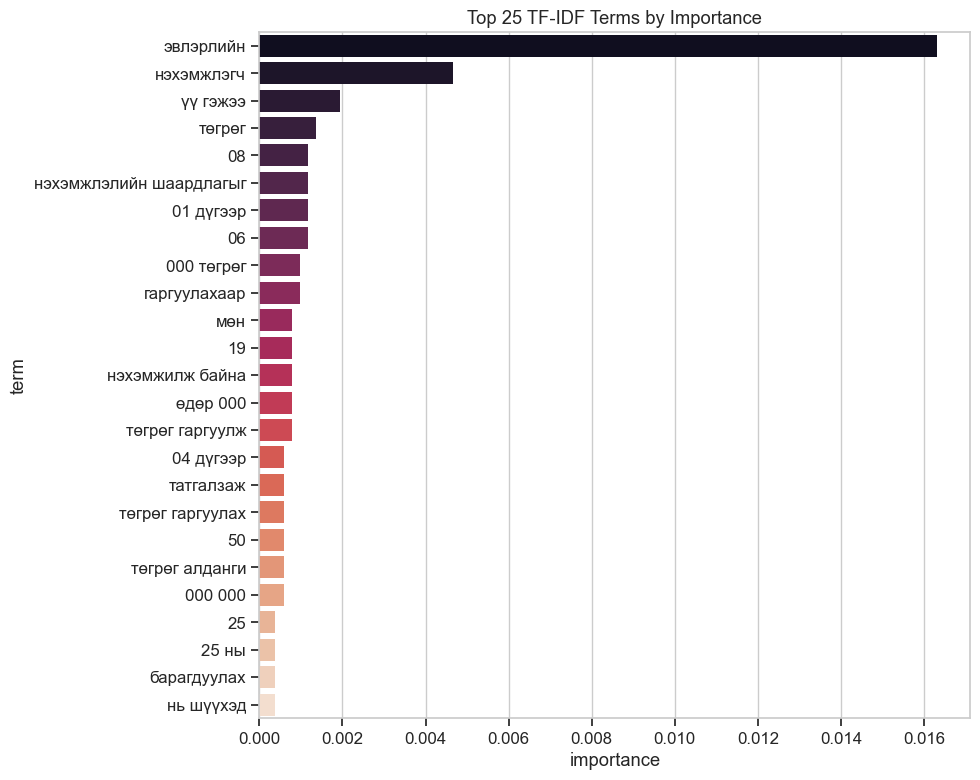

In [12]:
tf_df = pd.read_csv(f"{TABLES_DIR}/12_tfidf_top_features.csv")
plt.figure(figsize=(10, 8))
sns.barplot(x='importance', y='term', data=tf_df.head(25), palette='rocket')
plt.title('Top 25 TF-IDF Terms by Importance')
plt.tight_layout()
plt.show()

## 10. Per-Class F1 Score (HistGBM)

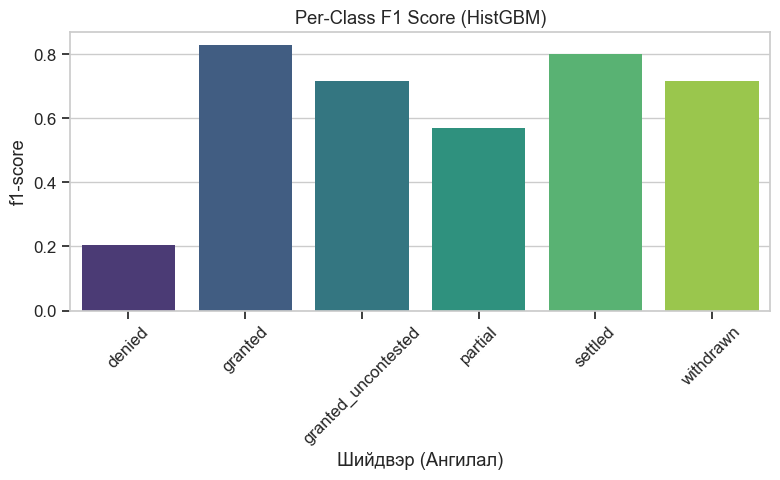

In [13]:
clf_rep = pd.read_csv(f"{TABLES_DIR}/13_classification_report.csv", index_col=0)
classes_only = clf_rep[~clf_rep.index.isin(['accuracy', 'macro avg', 'weighted avg'])]
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=classes_only.index, y='f1-score', data=classes_only, palette=COLOR_PALETTE)
ax.set_xlabel('Шийдвэр (Ангилал)')
plt.title('Per-Class F1 Score (HistGBM)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10.5 Per-Class Precision, Recall, and F1-Score (HistGBM)

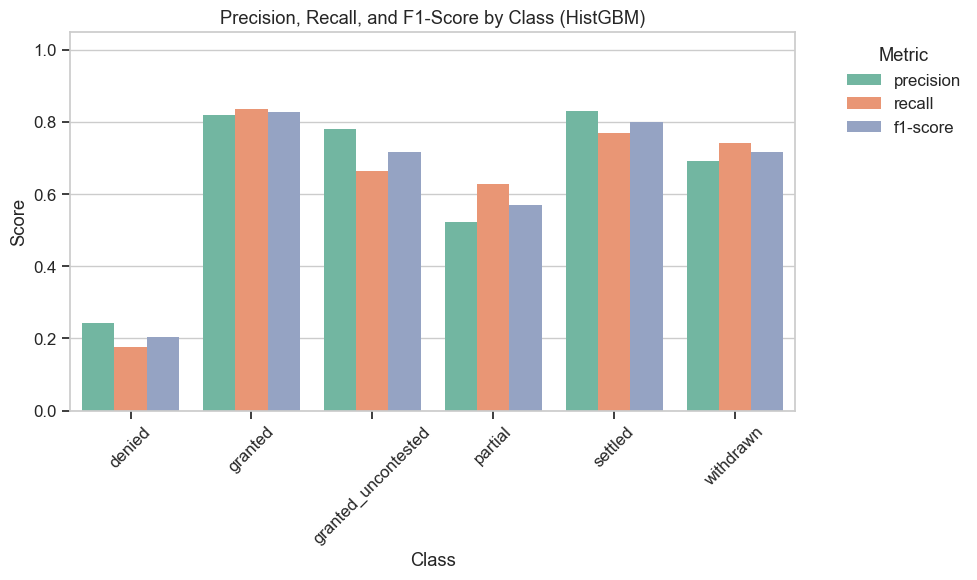

In [14]:
clf_rep = pd.read_csv(f"{TABLES_DIR}/13_classification_report.csv", index_col=0)
classes_only = clf_rep[~clf_rep.index.isin(['accuracy', 'macro avg', 'weighted avg'])].copy()
classes_only.reset_index(inplace=True)
classes_only.rename(columns={'index': 'Class'}, inplace=True)
melted_clf = classes_only.melt(id_vars='Class', value_vars=['precision', 'recall', 'f1-score'], var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
sns.barplot(x='Class', y='Score', hue='Metric', data=melted_clf, palette='Set2')
plt.title('Precision, Recall, and F1-Score by Class (HistGBM)')
plt.ylim(0, 1.05)
plt.xticks(rotation=45)
plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 11. Confusion Matrix (HistGBM)

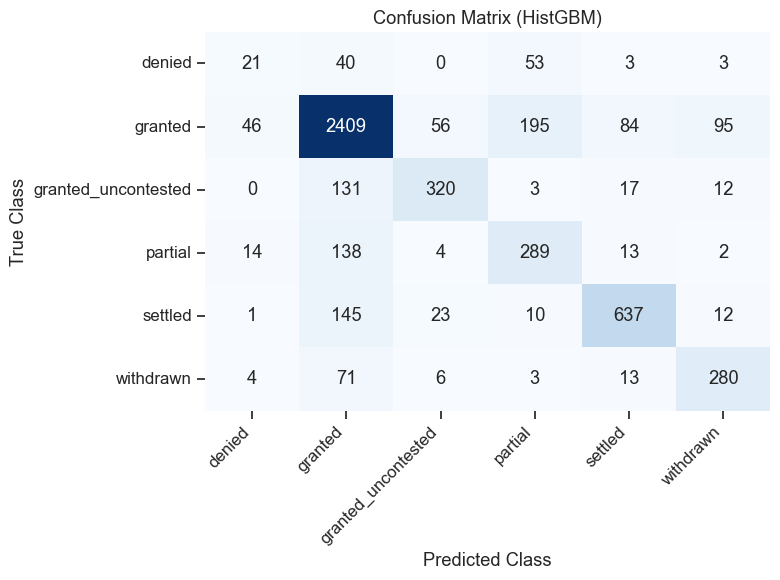

In [15]:
cm = pd.read_csv(f"{TABLES_DIR}/14_confusion_matrix.csv", index_col=0)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix (HistGBM)')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Normalized Confusion Matrix (HistGBM)

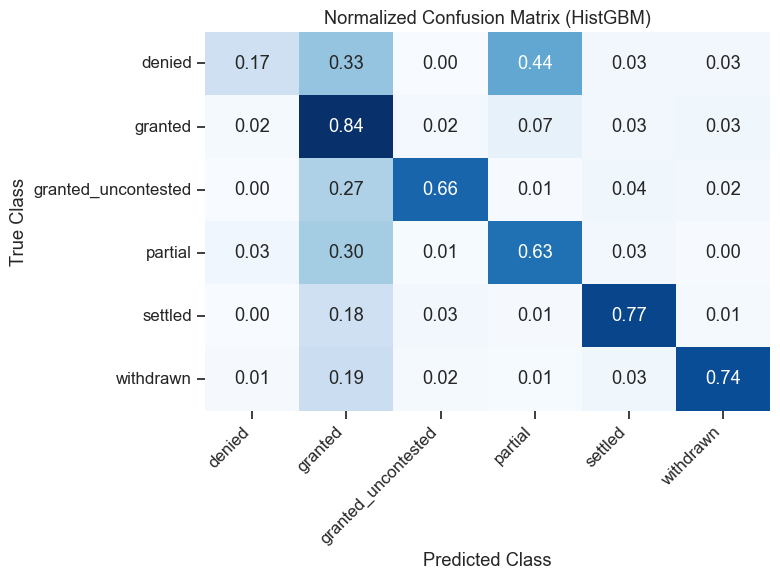

In [16]:
cm_norm = cm.div(cm.sum(axis=1), axis=0)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False)
plt.title('Normalized Confusion Matrix (HistGBM)')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 13. Calibration Curve

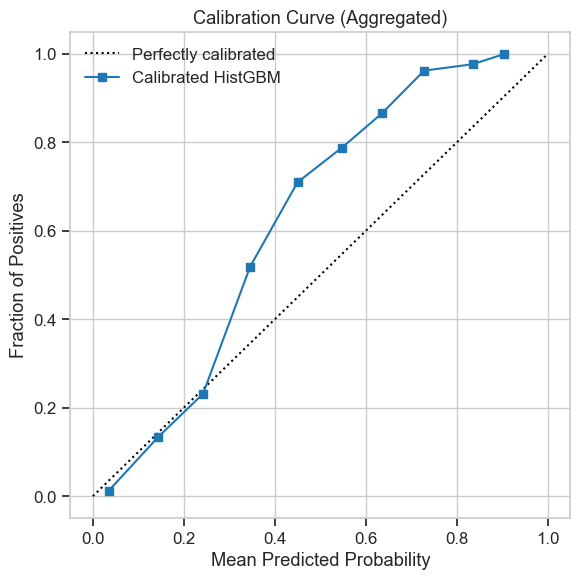

In [17]:
cal = pd.read_csv(f"{TABLES_DIR}/15_calibration.csv")
cal_agg = cal.dropna(subset=['fraction_positives']).groupby('bin_min')[['mean_predicted_prob', 'fraction_positives']].mean()
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k:', label='Perfectly calibrated')
plt.plot(cal_agg['mean_predicted_prob'], cal_agg['fraction_positives'], 's-', label='Calibrated HistGBM')
plt.title('Calibration Curve (Aggregated)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.tight_layout()
plt.show()

## 14. Accuracy

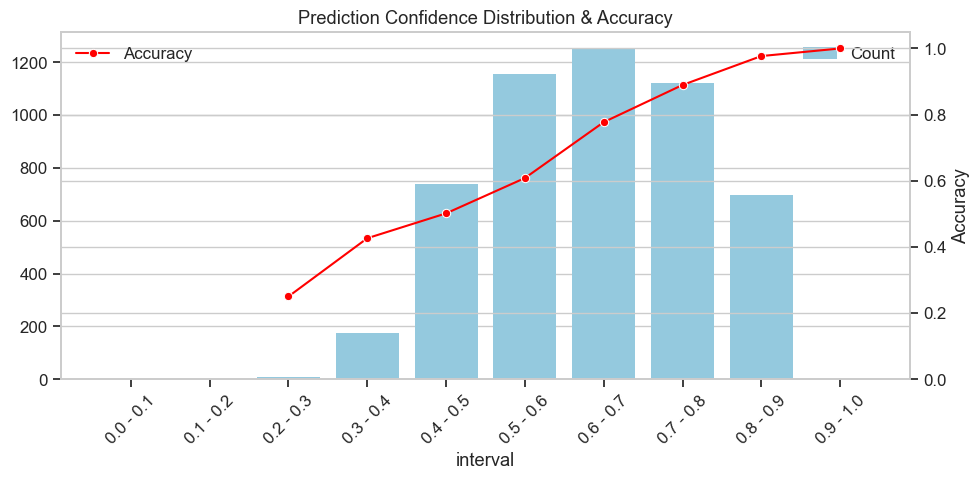

In [18]:
conf = pd.read_csv(f"{TABLES_DIR}/16_prediction_confidence.csv")
conf['interval'] = conf['bin_min'].round(2).astype(str) + ' - ' + conf['bin_max'].round(2).astype(str)
plt.figure(figsize=(10, 5))
ax1 = sns.barplot(x='interval', y='count', data=conf, color='skyblue', label='Count')
ax2 = ax1.twinx()
sns.lineplot(x='interval', y='accuracy', data=conf, color='red', marker='o', ax=ax2, label='Accuracy')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.set_title('Prediction Confidence Distribution & Accuracy')
ax1.set_ylabel('')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## 15. Appellate Target Distribution

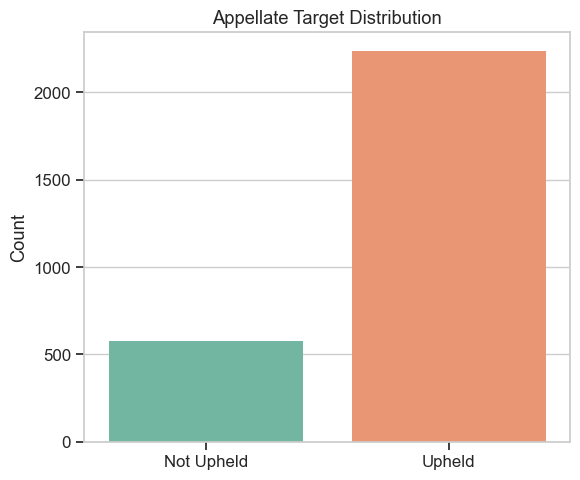

In [19]:
app_summary = pd.read_csv(f"{TABLES_DIR}/18_appellate_dataset_summary.csv").iloc[0]
plt.figure(figsize=(6, 5))
sns.barplot(x=['Not Upheld', 'Upheld'], y=[app_summary['not_upheld_count'], app_summary['upheld_count']], palette='Set2')
plt.title('Appellate Target Distribution')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 16. Appellate Odds Ratios

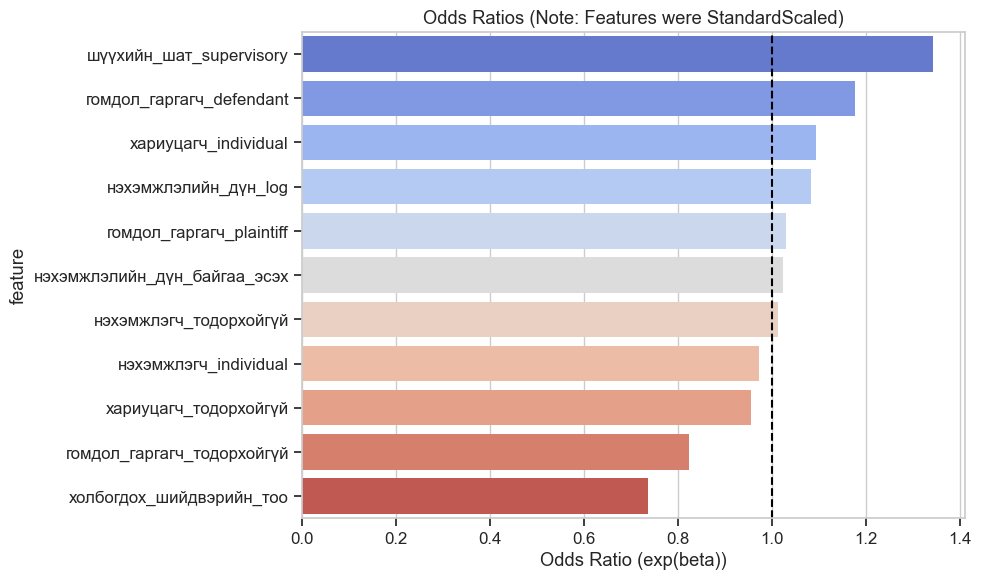

In [20]:
or_df = pd.read_csv(f"{TABLES_DIR}/20_odds_ratios.csv")
plt.figure(figsize=(10, 6))
sns.barplot(x='odds_ratio', y='feature', data=or_df, palette='coolwarm')
plt.axvline(x=1, color='black', linestyle='--')
plt.title('Odds Ratios (Note: Features were StandardScaled)')
plt.xlabel('Odds Ratio (exp(beta))')
plt.tight_layout()
plt.show()

## 17. Logistic Regression CV Performance

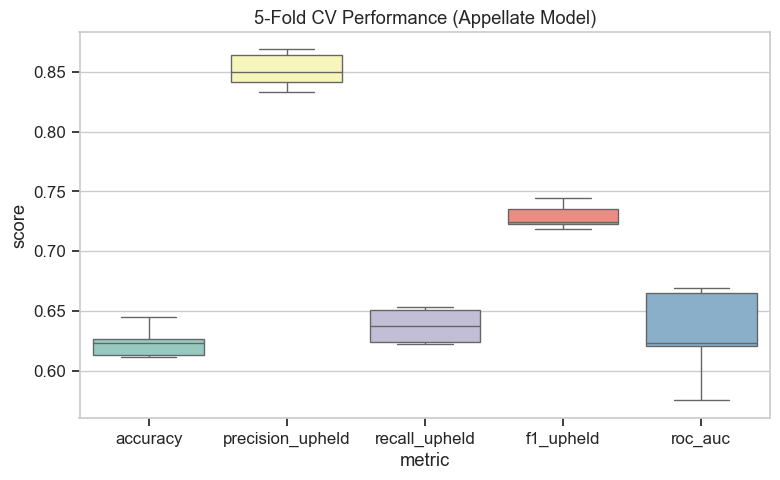

In [21]:
perf_df = pd.read_csv(f"{TABLES_DIR}/21_logistic_cv_results.csv")
melted_perf = perf_df[perf_df.fold != 'Mean'].melt(id_vars='fold', var_name='metric', value_name='score')
plt.figure(figsize=(8, 5))
sns.boxplot(x='metric', y='score', data=melted_perf, palette='Set3')
plt.title('5-Fold CV Performance (Appellate Model)')
plt.tight_layout()
plt.show()

## 18. Appellate Logistic Regression Confusion Matrix

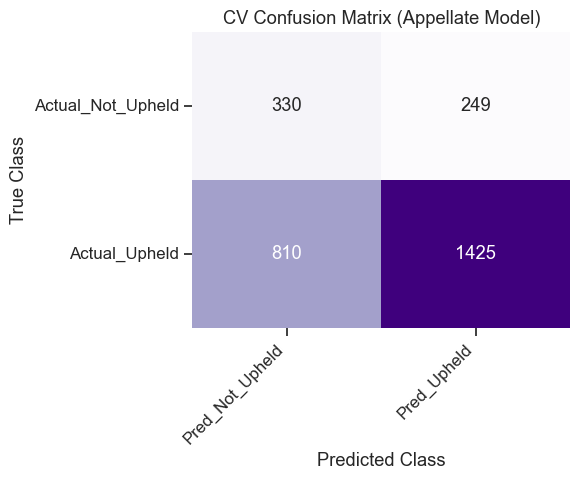

In [22]:
cm_app = pd.read_csv(f"{TABLES_DIR}/22_logistic_confusion_matrix.csv", index_col=0)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_app, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.title('CV Confusion Matrix (Appellate Model)')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 19. Receiver Operating Characteristic and PR Curves (Appellate)

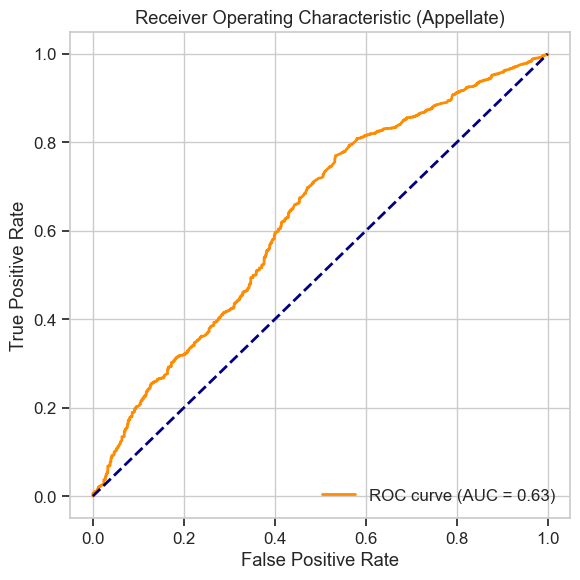

In [23]:
# Build pipeline to extract probabilities for ROC & PR curves
model_df = df[df['case_level'].isin(['appellate', 'supervisory'])].copy()
model_df = model_df[model_df['appeal_outcome'].notna()].copy()
model_df['шийдвэр_хэвээр'] = (model_df['appeal_outcome'] == 'upheld').astype(int)
model_df['нэхэмжлэлийн_дүн_байгаа_эсэх'] = model_df['claim_amount_requested'].notna().astype(int)
model_df['нэхэмжлэлийн_дүн_log'] = np.log1p(model_df['claim_amount_requested'].fillna(0))
model_df['нэхэмжлэгч'] = model_df['plaintiff_type'].fillna('тодорхойгүй')
model_df['хариуцагч'] = model_df['defendant_type'].fillna('тодорхойгүй')
model_df['шүүхийн_шат'] = model_df['case_level'].fillna('тодорхойгүй')
model_df['гомдол_гаргагч'] = model_df['appealing_party'].fillna('тодорхойгүй')
model_df['холбогдох_шийдвэрийн_тоо'] = model_df['referenced_decisions'].fillna('').apply(lambda x: len(x.split('|')) if x else 0)

feature_cols_numeric = ['нэхэмжлэлийн_дүн_log', 'нэхэмжлэлийн_дүн_байгаа_эсэх', 'холбогдох_шийдвэрийн_тоо']
dummies = pd.get_dummies(model_df[['нэхэмжлэгч', 'хариуцагч', 'шүүхийн_шат', 'гомдол_гаргагч']], drop_first=True)
X = pd.concat([model_df[feature_cols_numeric].reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)
y = model_df['шийдвэр_хэвээр'].reset_index(drop=True)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', random_state=42)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_prob = cross_val_predict(pipe, X, y, cv=cv, method='predict_proba')[:, 1]

fpr, tpr, _ = roc_curve(y, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Appellate)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 20. Precision-Recall Curve (Appellate)

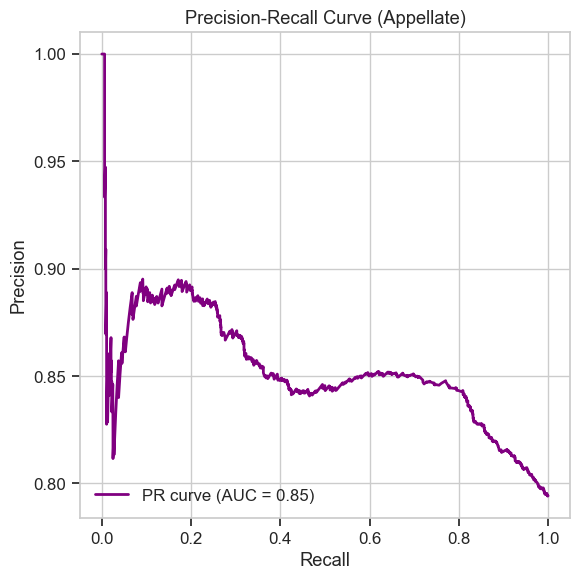

In [24]:
precision, recall, _ = precision_recall_curve(y, y_prob)
pr_auc = auc(recall, precision)
plt.figure(figsize=(6, 6))
plt.plot(recall, precision, color='purple', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Appellate)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()